# Assignment 11: Spatial community composition in California

## BIO597 Spatial Analysis of Biodiversity

Repeat the [Lab11](../labs/Lab11-SpatialCommunityComposition.ipynb) analysis for
California. How do grid grain, geographic distance, and climate affect our view
of amphibian communities across this larger and environmentally varied state?

Use **20, 40, and 80 km cells**. Follow the lab's sequence: community matrices,
richness, distance decay, neighboring-community differences, GDM at each grain,
and a PCA map/biplot of all 19 GDM-transformed bioclimatic predictors. You may reuse the lab's analysis
code. Spatial preparation helpers are supplied below.

Submit this notebook with figures, summary tables, short answers, and a
**400–600 word synthesis**. Cite the GBIF download DOI and the boundary and
climate sources.

## Inputs and environment

Run from `docs/assignments` using the Lab11 environment, including `gdmbayes`,
GeoPandas and Rasterio.

| Input | Path from this notebook |
| --- | --- |
| California boundary, including islands | `../data/CA_ShapeFiles/California_State_Boundary.shp` |
| GBIF amphibian occurrences | `../data/CA_amphibians.geojson` |
| All 19 clipped WorldClim layers | `../data/bioclim_CA` |

All inputs are provided. The occurrence GeoJSON is a reproducible random
sample of California records from the GBIF download, reduced to about **20 MB**
and using the same fields as the california data. See the
[California data notes](../data/CA_data_README.md) for filtering, sample size,
and provenance. Record the download DOI here:

*GBIF download DOI:* [10.15468/dl.wbj54a](https://doi.org/10.15468/dl.wbj54a)

## 1. Load and inspect the California data

Use **California Albers (EPSG:3310)** for the grid and approximate geographic
distances in meters. California spans more than one UTM zone, so do not reuse
california's UTM projection or grid origin.

The occurrence file contains amphibian detections within the California
boundary. It was randomly sampled after clipping. Drop records without a species
name before constructing communities. The six fields
match california's data: GBIF ID, species, longitude, latitude, coordinate uncertainty,
and year. Random downsampling can remove observations of rarely recorded species.

In [1]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.mask import mask
from shapely.geometry import box
from scipy.spatial.distance import pdist, squareform
from gdmbayes import GDM

CRS = "EPSG:3310"
GRAINS = [20, 40, 80]
MIN_RECORDS = 1
CLIMATE_DIR = Path("../data/bioclim_CA")
OUTPUT = Path("outputs/Assignment11")
OUTPUT.mkdir(parents=True, exist_ok=True)

california = gpd.read_file("../data/CA_ShapeFiles/California_State_Boundary.shp")
california = california.to_crs(CRS).dissolve()
records = gpd.read_file("../data/CA_amphibians.geojson").to_crs(CRS)
print("Input records:", len(records))
records = records.dropna(subset=["species"])
records = records[records.species != ""]
records = gpd.clip(records, california)
print("Sampled records with species names:", len(records))
print("Species labels:", records.species.nunique())

Input records: 71578
Sampled records with species names: 62829
Species labels: 89


california records: 62829
Species labels: 89


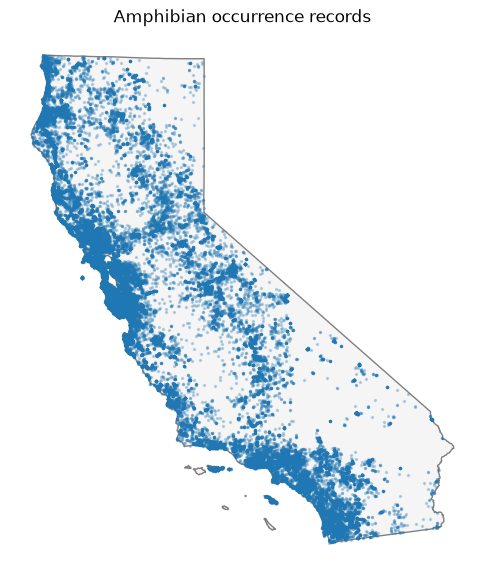

In [2]:
# Map the boundary and occurrence points.
# Inspect record years and coordinateUncertaintyInMeters.
# Consider sampling gaps, repeated locations, and coordinate uncertainty.
california = gpd.read_file("/home/jovyan/BIO597-SpatialBiodiversity/docs/data/CA_ShapeFiles/California_State_Boundary.shp").to_crs(CRS).dissolve()
records = gpd.read_file("../data/CA_amphibians.geojson").to_crs(CRS)
records = records.dropna(subset=["species"])
records = records[records.species != ""]
records = gpd.clip(records, california)

print("california records:", len(records))
print("Species labels:", records.species.nunique())

ax = california.plot(color="whitesmoke", edgecolor="gray", figsize=(6, 7))
records.plot(ax=ax, markersize=2, alpha=0.25)
ax.set_title("Amphibian occurrence records")
ax.set_axis_off()
plt.show()

**Interpretation:** Where are observations concentrated or sparse? Which parts
of California might be especially difficult to characterize from these data?
Explain why repeated records, uncertain coordinates, and unresolved species
names matter for a site-by-species matrix.

*Your answer:* They were concentrated on the coast, but sparse in eastern California. The parts that we know have fewer people and fewer researchers studying them. I mean if we do not know where a record was actually found, whether or not it is a new and independent data point, or what species it is, our site-by-species matrix, might have some issues.

## 2. Aggregate records to sites

The helper follows Lab11 but uses the California boundary and a new shared grid
origin. Finer cells nest within coarser cells. Only cells meeting `MIN_RECORDS`
become sites; missing cells are not treated as zero-richness communities.

Map outlines are clipped to the state, but geographic distances use the full
square centers. Coastal and island cells can contain less land than interior
cells of the same nominal grain.

In [3]:
origin_width = max(GRAINS) * 1000
x0 = np.floor(california.total_bounds[0] / origin_width) * origin_width
y0 = np.floor(california.total_bounds[1] / origin_width) * origin_width


def grid_communities(grain_km):
    width = grain_km * 1000
    points = records.copy()
    points["col"] = ((points.geometry.x - x0) // width).astype(int)
    points["row"] = ((points.geometry.y - y0) // width).astype(int)
    points["site_id"] = points.col.astype(str) + "_" + points.row.astype(str)
    community = pd.crosstab(points.site_id, points.species)
    cell_locations = points[["site_id", "col", "row"]].drop_duplicates()
    cells = []
    for cell in cell_locations.itertuples():
        x = x0 + cell.col * width
        y = y0 + cell.row * width
        cells.append({"site_id": cell.site_id, "xc": x + width / 2,
                      "yc": y + width / 2, "geometry": box(x, y, x + width, y + width)})
    sites = gpd.GeoDataFrame(cells, crs=CRS).set_index("site_id")
    sites = gpd.clip(sites, california).sort_index()
    community = community.reindex(sites.index)
    sites["n_records"] = community.sum(axis=1)
    sites["richness"] = (community > 0).sum(axis=1)
    sites = sites[sites.n_records >= MIN_RECORDS].copy()
    return sites, community.loc[sites.index]

In [4]:
sites_by_grain = {}
communities = {}
grain_summary = pd.DataFrame()

# Loop over GRAINS and call grid_communities(grain).
# Store sites_by_grain[grain] and communities[grain], as in Lab11.
# Summarize n_sites, n_records, mean_richness, and median_records_per_site.
# Display grain_summary and the first rows of communities[40].

sites_by_grain = {}
communities = {}
grain_summary = pd.DataFrame()

for grain in GRAINS:
    sites, community = grid_communities(grain)
    sites_by_grain[grain] = sites
    communities[grain] = community
    grain_summary.loc[grain, "n_sites"] = len(sites)
    grain_summary.loc[grain, "n_records"] = sites.n_records.sum()
    grain_summary.loc[grain, "mean_richness"] = sites.richness.mean()
    grain_summary.loc[grain, "median_records_per_site"] = sites.n_records.median()

grain_summary.index.name = "grain_km"
display(grain_summary)
display(communities[40].head())

,n_sites,n_records,mean_richness,median_records_per_site
grain_km,,,,
20,893.0,62829.0,5.456887,19.0
40,278.0,62829.0,8.017986,66.5
80,88.0,62829.0,11.681818,292.0


species,Ambystoma californiense,Ambystoma gracile,Ambystoma macrodactylum,Ambystoma mavortium,Ambystoma texanum,Ambystoma tigrinum,Amerana aurora,Amerana boylii,Amerana cascadae,Amerana draytonii,...,Rhyacotriton variegatus,Scaphiopus couchii,Scaphiopus hurterii,Spea hammondii,Spea intermontana,Taricha granulosa,Taricha rivularis,Taricha sierrae,Taricha torosa,Xenopus laevis
site_id,,,,,,,,,,,,,,,,,,,,,
0_22,0,0,0,0,0,0,0,5,0,0,...,0,0,0,0,0,1,0,0,0,0
0_23,0,0,0,0,0,0,3,3,0,0,...,0,0,0,0,0,1,0,0,0,0
10_10,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
10_11,0,0,0,0,0,0,0,0,0,0,...,0,0,0,3,0,0,0,0,0,0
10_12,1,0,0,0,0,0,0,0,0,0,...,0,0,0,4,0,0,0,9,0,0


## 3. Richness and sampling maps

Plot richness for all three grains using one shared color scale. Make a second
comparison of record counts and richness at 20 km. Use `california` as the
background layer when adapting the lab's mapping cells.

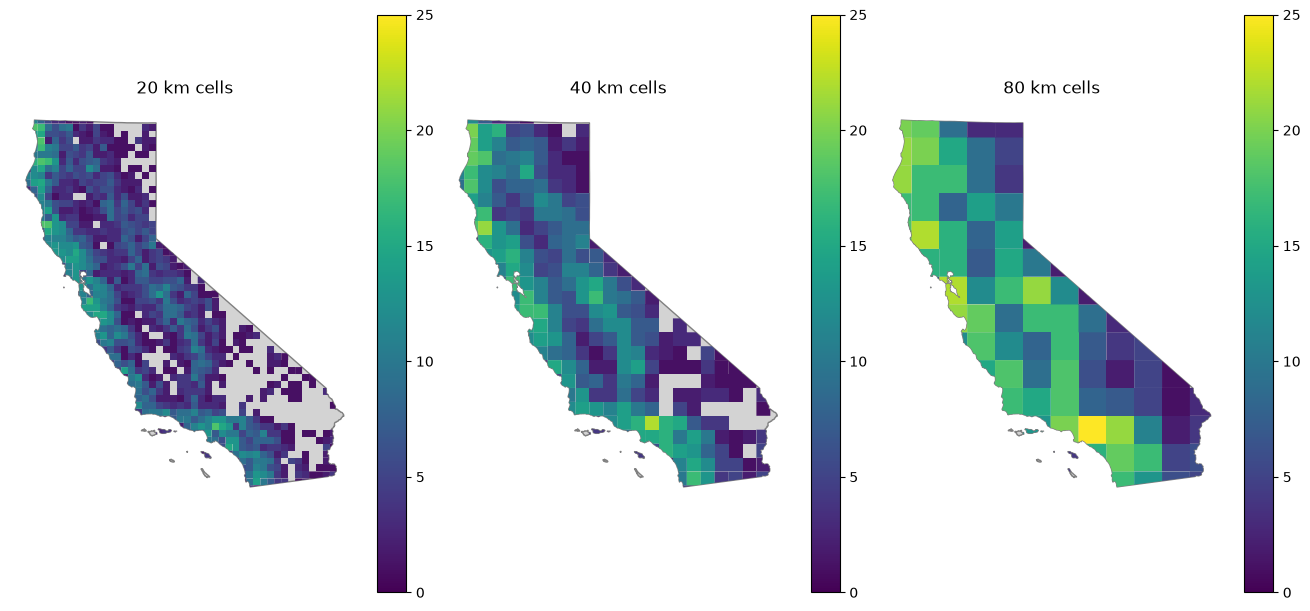

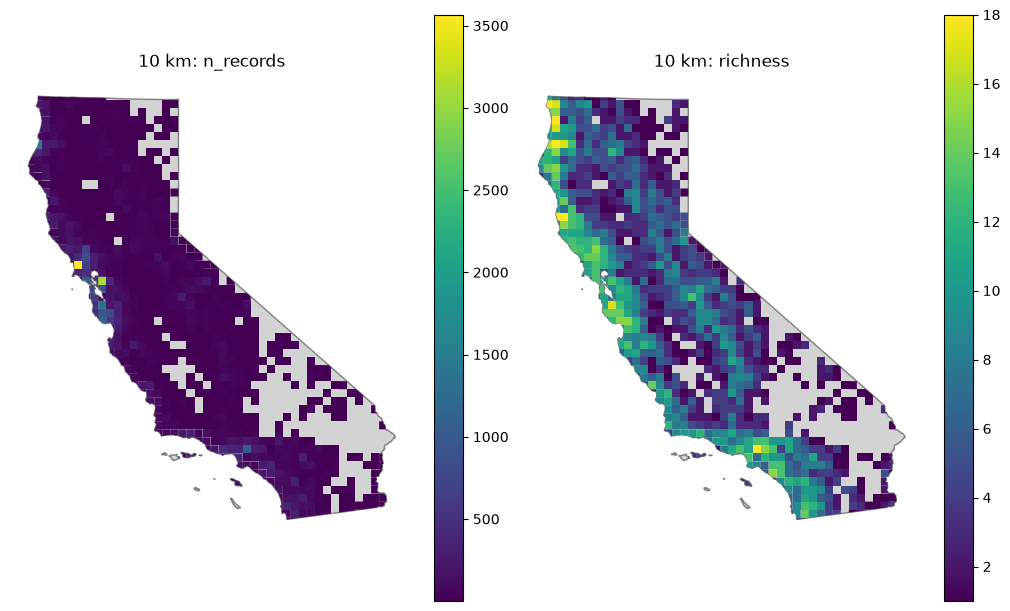

In [5]:
# Create and save the three richness maps with a common color scale.
# Compare n_records and richness at 20 km.
max_richness = max(sites.richness.max() for sites in sites_by_grain.values())
fig, axes = plt.subplots(1, 3, figsize=(13, 6), layout="constrained")
for ax, grain in zip(axes, GRAINS):
    california.plot(ax=ax, color="lightgray", edgecolor="gray")
    sites_by_grain[grain].plot(ax=ax, column="richness", cmap="viridis",
                              vmin=0, vmax=max_richness, legend=True)
    ax.set_title(f"{grain} km cells")
    ax.set_axis_off()
fig.savefig(OUTPUT / "richness_by_grain.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 6), layout="constrained")
for ax, column in zip(axes, ["n_records", "richness"]):
    california.plot(ax=ax, color="lightgray", edgecolor="gray")
    sites_by_grain[20].plot(ax=ax, column=column, legend=True)
    ax.set_title(f"10 km: {column}")
    ax.set_axis_off()
plt.show()

**Interpretation:** Which richness patterns persist across grains? Which become
more or less apparent? How much might the patterns reflect aggregation,
reporting effort, or differences in the amount of land within a cell?

*Your answer:* There is a high amount of richness on the coast compared to the center of the state across maps. The richness would appear to increase for cells on the east side of California as grain size increases because the cells include a wider area which allows them to capture more unique species. This pattern is definitely due in part to the differences in the amount of land within a cell and the aggregation of several smaller cells into one combined cell. The pattern could reflect reporter error, but I do not know what the level of uncertainty was regarding the coordinates of each sample or the methods used to collect all the data. 

## 4. Distance decay of similarity

Use presence/absence and **Jaccard dissimilarity**. Similarity is `1 - Jaccard`.
The helpers below retain matching site order and summarize similarity in
100 km distance bands, allowing for California's larger extent.

Plot all pairs and their distance-band means for each grain. Keep similarity
axes fixed at 0–1. Report the descriptive Spearman distance–similarity
correlation, without treating pairs that share sites as independent replicates.

In [6]:
def community_pairs(sites, community):
    presence = community.loc[sites.index] > 0
    dissimilarity = pdist(presence, metric="jaccard")
    distance_km = pdist(sites[["xc", "yc"]]) / 1000
    return pd.DataFrame({"distance_km": distance_km,
                         "jaccard": dissimilarity,
                         "similarity": 1 - dissimilarity})


def distance_bands(pairs):
    rows = []
    for lower in range(0, 1600, 100):
        in_band = pairs[(pairs.distance_km >= lower) & (pairs.distance_km < lower + 100)]
        if len(in_band) == 0:
            continue
        rows.append({"distance_km": in_band.distance_km.mean(),
                     "mean_similarity": in_band.similarity.mean(),
                     "n_pairs": len(in_band)})
    return pd.DataFrame(rows)

,distance_km,jaccard,similarity
0,20.0,0.142857,0.857143
1,40.0,0.294118,0.705882
2,60.0,0.461538,0.538462
3,80.0,0.250000,0.750000
4,100.0,0.437500,0.562500


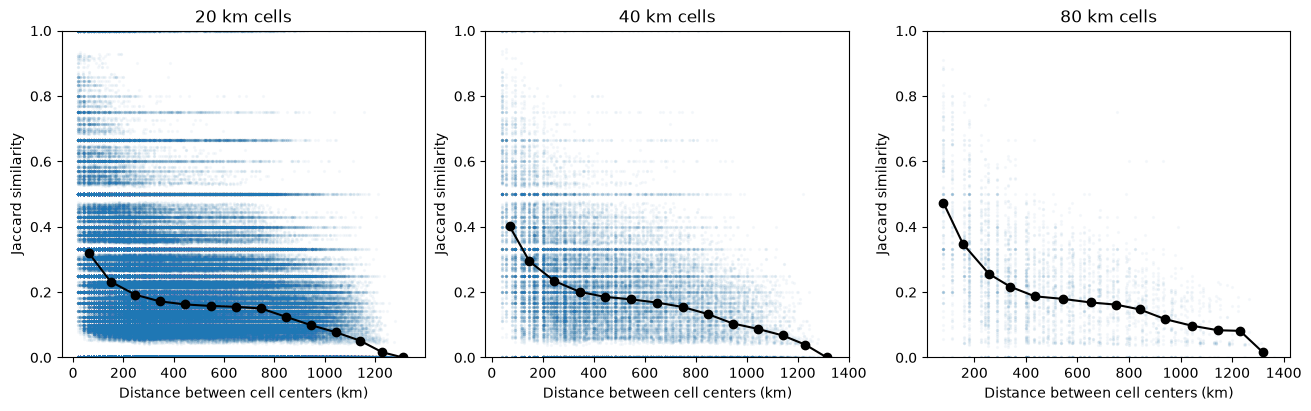

,n_sites,n_records,mean_richness,median_records_per_site,distance_similarity_rho
grain_km,,,,,
20,893.0,62829.0,5.456887,19.0,-0.265722
40,278.0,62829.0,8.017986,66.5,-0.385445
80,88.0,62829.0,11.681818,292.0,-0.456623


In [7]:
pairs_by_grain = {}
for grain in GRAINS:
    pairs_by_grain[grain] = community_pairs(sites_by_grain[grain], communities[grain])

display(pairs_by_grain[20].head())

# For each grain, calculate community_pairs and distance_bands.
# Make distance-decay plots and calculate the descriptive correlation.
# Inspect n_pairs in the most distant bands before interpreting their means.
binned_decay = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, grain in zip(axes, GRAINS):
    pairs = pairs_by_grain[grain]
    bands = distance_bands(pairs)
    binned_decay[grain] = bands
    ax.scatter(pairs.distance_km, pairs.similarity, s=2, alpha=0.03)
    ax.plot(bands.distance_km, bands.mean_similarity, color="black", marker="o")
    ax.set(title=f"{grain} km cells", xlabel="Distance between cell centers (km)",
           ylabel="Jaccard similarity", ylim=(0, 1))
    grain_summary.loc[grain, "distance_similarity_rho"] = pairs.distance_km.corr(
        pairs.similarity, method="spearman")
fig.savefig(OUTPUT / "distance_decay_by_grain.png", dpi=150)
plt.show()

display(grain_summary)


**Interpretation:** Does similarity decline steadily, level off, or show another
pattern? How does the relationship change with grain? Explain at least two
biological or sampling explanations. Could nested species lists contribute to
Jaccard dissimilarity without species replacement?

*Your answer:* Similarity forms a pattern where it declines, levels off, and then declines again. The trendline becomes flatter and more level for longer as grain increases, but the inital similarity metric is higher at geographically close cells when grain size increases. A larger grain size could mean that each cell is more uniform because it is includes a wider area and is more likely to include distinct environmental features. Basically as grain size increases the cells become more uniform. A larger grain size artificially inflates the species richness because the cells are larger.

## 5. Local differences among communities

Reuse the lab's neighbor comparison: mean Jaccard dissimilarity to sampled
cells within **1.5 cell widths**, excluding the focal cell. Map the results for
all three grains with one 0–1 color scale. Leave cells with no sampled neighbors
as missing.

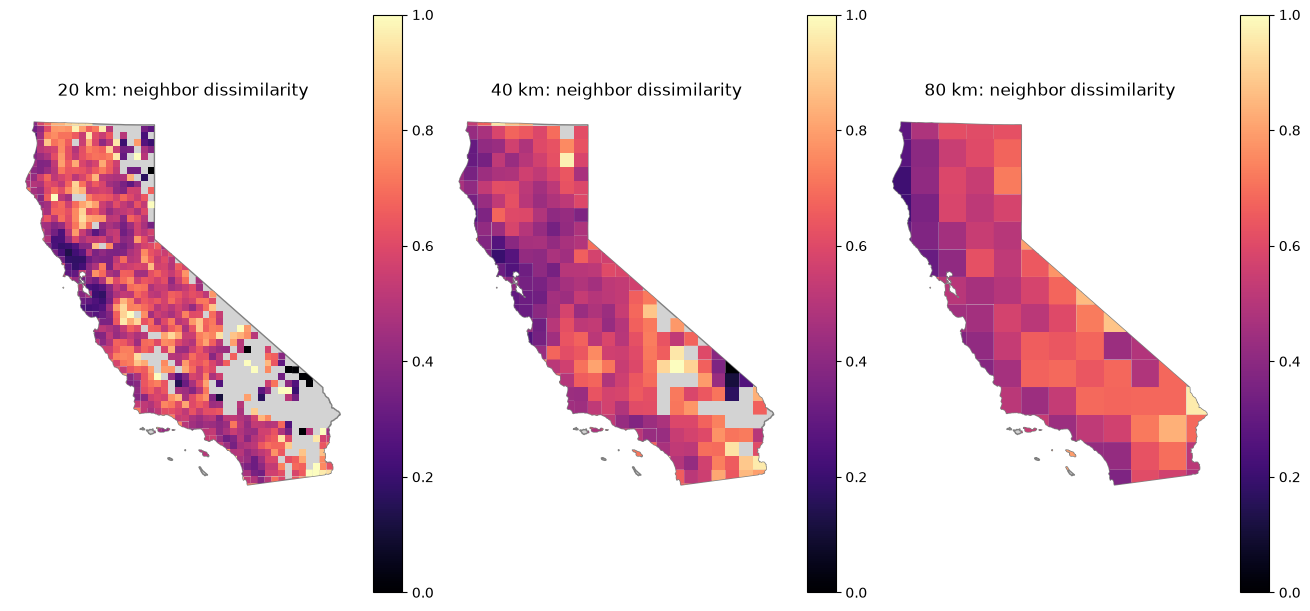

               xc        yc  \
site_id                       
11_3     520000.0 -360000.0   
8_6      280000.0 -120000.0   
7_7      200000.0  -40000.0   
10_2     440000.0 -440000.0   
5_9       40000.0  120000.0   

                                                  geometry  n_records  \
site_id                                                                 
11_3     POLYGON ((480000 -400000, 480000 -320000, 4879...         30   
8_6      POLYGON ((240000 -160000, 240000 -102030.163, ...          3   
7_7      POLYGON ((160000 -80000, 160000 -31519.316, 16...        124   
10_2     POLYGON ((400000 -480000, 400000 -400000, 4800...         12   
5_9      POLYGON ((0 80000, 0 109214.975, 4210.765 1055...         12   

         richness  neighbor_dissimilarity  
site_id                                    
11_3            3                0.958333  
8_6             3                0.875873  
7_7             2                0.856471  
10_2            2                0.832639  
5_9   

In [8]:
# Use squareform on each grain's distance and dissimilarity vectors.
# Calculate neighbor_dissimilarity for each sampled cell.
# Map and save the three results.

for grain in GRAINS:
    sites = sites_by_grain[grain]
    pairs = pairs_by_grain[grain]
    distances = squareform(pairs.distance_km.to_numpy())
    dissimilarities = squareform(pairs.jaccard.to_numpy())
    local_difference = []
    for i in range(len(sites)):
        neighbors = (distances[i] > 0) & (distances[i] <= 1.5 * grain)
        if neighbors.any():
            local_difference.append(dissimilarities[i, neighbors].mean())
        else:
            local_difference.append(np.nan)
    sites["neighbor_dissimilarity"] = local_difference

fig, axes = plt.subplots(1, 3, figsize=(13, 6), layout="constrained")
for ax, grain in zip(axes, GRAINS):
    california.plot(ax=ax, color="lightgray", edgecolor="gray")
    sites_by_grain[grain].plot(ax=ax, column="neighbor_dissimilarity", cmap="magma",
                              vmin=0, vmax=1, legend=True)
    ax.set_title(f"{grain} km: neighbor dissimilarity")
    ax.set_axis_off()
fig.savefig(OUTPUT / "CA_neighbor_dissimilarity_by_grain.png", dpi=150)
plt.show()
print(sites.sort_values(by="neighbor_dissimilarity", ascending=False).head())

**Interpretation:** Where are neighboring recorded communities most different?
Choose two contrasting sites and inspect their species lists and record totals.
Why is this not a map of pure species replacement or turnover per kilometer?

*Your answer:* Across all three plots the most different communities are in the Southeast. Site 11_3 has a dissimilarity measure of 0.95, 30 records, and a richness of 3. Site 8_6 has a dissimilarity measure of 0.87, 3 records, and 3 species.

## 6. Summarize site climate

Use **all 19 bioclimatic variables**, matching the revised Lab11 and its
predictor names. Each site's climate is the mean of valid raster pixels
intersecting its land area. Edge pixels are included equally; this is an
approximate zonal mean, not an exact area-weighted average.

Inspect the ranges and correlations of all predictors. For orientation, map
`temperature_c` (BIO1) and `precip` (BIO12) at 40 km. These are example maps;
**all 19 variables enter every full GDM and the PCA**. Several predictors describe
related aspects of climate, so their fitted contributions can overlap.

In [9]:
CLIMATE_LAYERS = {
    'wc2.1_2.5m_bio_1.tif': 'temperature_c',
    'wc2.1_2.5m_bio_2.tif': 'diurnal_range_c',
    'wc2.1_2.5m_bio_3.tif': 'isothermality',
    'wc2.1_2.5m_bio_4.tif': 'temp_seasonality',
    'wc2.1_2.5m_bio_5.tif': 'max_temp_warmest',
    'wc2.1_2.5m_bio_6.tif': 'min_temperature_coldest',
    'wc2.1_2.5m_bio_7.tif': 'temp_range',
    'wc2.1_2.5m_bio_8.tif': 'temp_wettest_q',
    'wc2.1_2.5m_bio_9.tif': 'temp_driest_q',
    'wc2.1_2.5m_bio_10.tif': 'temp_warmest_q',
    'wc2.1_2.5m_bio_11.tif': 'temp_coldest_q',
    'wc2.1_2.5m_bio_12.tif': 'precip',
    'wc2.1_2.5m_bio_13.tif': 'precip_wettest_m',
    'wc2.1_2.5m_bio_14.tif': 'precip_driest_m',
    'wc2.1_2.5m_bio_15.tif': 'precip_seasonality',
    'wc2.1_2.5m_bio_16.tif': 'precip_wettest_q',
    'wc2.1_2.5m_bio_17.tif': 'precip_driest_q',
    'wc2.1_2.5m_bio_18.tif': 'precip_warmest_q',
    'wc2.1_2.5m_bio_19.tif': 'precip_coldest_q',
}

predictors = list(CLIMATE_LAYERS.values())


def add_climate(sites, climate_dir=CLIMATE_DIR):
    sites = sites.copy()
    for filename, name in CLIMATE_LAYERS.items():
        means = []
        with rasterio.open(climate_dir / filename) as raster:
            raster_sites = sites.to_crs(raster.crs)
            for geometry in raster_sites.geometry:
                pixels, transform = mask(raster, [geometry], crop=True,
                                         filled=False, all_touched=True)
                valid_pixels = pixels[0].compressed()
                if len(valid_pixels) == 0:
                    means.append(np.nan)
                else:
                    means.append(valid_pixels.mean())
        sites[name] = means
    return sites

In [10]:
climate_sites = {}

# Call add_climate for each grain using all 19 layers.
# Report missing climate values and inspect all predictor ranges and correlations.
# Map temperature_c and precip at 40 km as examples of the gradients.

CLIMATE_DIR = Path("../data/bioclim_CA")
predictors = list(CLIMATE_LAYERS.values())

def add_climate(sites):
    sites = sites.copy()
    for f, name in CLIMATE_LAYERS.items():
        path = CLIMATE_DIR / f
        means = []
        with rasterio.open(path) as raster:
            raster_sites = sites.to_crs(raster.crs)
            for geometry in raster_sites.geometry:
                pixels, transform = mask(raster, [geometry], crop=True,
                                         filled=False, all_touched=True)
                valid_pixels = pixels[0].compressed()
                if len(valid_pixels) == 0:
                    means.append(np.nan)
                else:
                    means.append(valid_pixels.mean())
        sites[name] = means
    return sites


climate_sites = {}
for grain in GRAINS:
    sites = add_climate(sites_by_grain[grain])
    climate_sites[grain] = sites
    print(grain, "km: sites missing climate =", sites[predictors].isna().any(axis=1).sum())

display(climate_sites[40][predictors].describe())
display(climate_sites[40][predictors].corr())

20 km: sites missing climate = 4
40 km: sites missing climate = 0
80 km: sites missing climate = 0


,temperature_c,diurnal_range_c,isothermality,temp_seasonality,max_temp_warmest,min_temperature_coldest,temp_range,temp_wettest_q,temp_driest_q,temp_warmest_q,temp_coldest_q,precip,precip_wettest_m,precip_driest_m,precip_seasonality,precip_wettest_q,precip_driest_q,precip_warmest_q,precip_coldest_q
count,278.000000,278.000000,278.000000,278.000000,278.000000,278.000000,278.000000,278.000000,278.000000,278.000000,278.000000,278.000000,278.000000,278.000000,278.000000,278.000000,278.000000,278.000000,278.000000
mean,13.832013,14.803650,48.475342,609.009583,31.400061,0.247471,31.152590,8.061214,20.037508,21.585320,6.858330,595.700623,109.224258,3.822259,75.839546,301.070862,20.608854,28.944468,291.707581
std,4.430192,1.871636,5.664179,163.874237,5.361005,4.438009,5.947634,5.762297,3.795028,4.990815,4.464513,421.025726,77.335999,3.753445,16.716801,215.833755,17.023989,18.085241,209.735184
min,2.834438,8.231700,38.435932,213.356339,20.172401,-12.047891,15.727080,-3.780253,10.774411,11.606176,-3.938595,70.151512,11.181818,0.000000,33.167458,28.208334,2.252525,2.252525,26.958334
25%,10.784941,14.036752,44.572820,517.374527,27.501352,-1.762038,28.720987,4.743511,16.860105,17.331770,4.166236,295.273468,50.363488,1.061090,63.304149,143.104401,6.609716,13.131944,136.631950
50%,14.510736,15.054690,46.681192,652.459991,30.853904,1.308185,32.597082,8.844189,20.279663,21.250464,8.180924,475.038254,90.822258,2.222222,81.590343,254.748817,13.379762,24.950000,244.831818
75%,16.649068,15.946422,51.930415,714.375763,35.397858,2.969394,35.356641,10.357427,23.188622,24.680593,9.383530,831.733307,152.113060,5.723961,88.045961,419.192001,36.067349,44.296551,413.397232
max,23.690939,19.615477,66.653465,886.652161,42.853413,8.815785,40.265675,30.898878,27.622074,33.392986,14.605829,1993.640015,350.359985,16.318182,106.078613,993.080017,68.480003,83.279999,937.599976


,temperature_c,diurnal_range_c,isothermality,temp_seasonality,max_temp_warmest,min_temperature_coldest,temp_range,temp_wettest_q,temp_driest_q,temp_warmest_q,temp_coldest_q,precip,precip_wettest_m,precip_driest_m,precip_seasonality,precip_wettest_q,precip_driest_q,precip_warmest_q,precip_coldest_q
temperature_c,1.000000,0.077211,-0.035312,0.129207,0.768262,0.808920,0.088886,0.903989,0.869090,0.913389,0.901166,-0.529365,-0.471582,-0.857736,0.063881,-0.477431,-0.808258,-0.630638,-0.479475
diurnal_range_c,0.077211,1.000000,-0.539873,0.756320,0.621325,-0.432395,0.882687,-0.110799,0.329317,0.375244,-0.254868,-0.407486,-0.454904,0.098293,-0.506458,-0.448962,0.044014,0.010970,-0.448007
isothermality,-0.035312,-0.539873,1.000000,-0.941848,-0.574271,0.461554,-0.862032,0.167167,-0.292382,-0.415921,0.374049,0.344383,0.414512,-0.242212,0.694426,0.417231,-0.192974,-0.205774,0.414667
temp_seasonality,0.129207,0.756320,-0.941848,1.000000,0.706632,-0.450160,0.972836,-0.088763,0.365929,0.519780,-0.310435,-0.456203,-0.523461,0.169502,-0.757002,-0.524960,0.111472,0.143290,-0.521677
max_temp_warmest,0.768262,0.621325,-0.574271,0.706632,1.000000,0.274501,0.696541,0.555918,0.866119,0.949880,0.429463,-0.618594,-0.620170,-0.506896,-0.380421,-0.622698,-0.486946,-0.365992,-0.623226
min_temperature_coldest,0.808920,-0.432395,0.461554,-0.450160,0.274501,1.000000,-0.498754,0.851844,0.573704,0.512565,0.971858,-0.118883,-0.031346,-0.851855,0.506031,-0.036742,-0.736523,-0.588018,-0.040637
temp_range,0.088886,0.882687,-0.862032,0.972836,0.696541,-0.498754,1.000000,-0.134542,0.352605,0.473725,-0.338077,-0.468872,-0.535611,0.178738,-0.720490,-0.533864,0.110661,0.108874,-0.531434
temp_wettest_q,0.903989,-0.110799,0.167167,-0.088763,0.555918,0.851844,-0.134542,1.000000,0.689814,0.743325,0.906554,-0.375966,-0.314928,-0.789174,0.149747,-0.320195,-0.731730,-0.525162,-0.324091
temp_driest_q,0.869090,0.329317,-0.292382,0.365929,0.866119,0.573704,0.352605,0.689814,1.000000,0.893256,0.670312,-0.530935,-0.493505,-0.751083,0.052874,-0.497497,-0.707153,-0.658166,-0.499119
temp_warmest_q,0.913389,0.375244,-0.415921,0.519780,0.949880,0.512565,0.473725,0.743325,0.893256,1.000000,0.650547,-0.639183,-0.617457,-0.665116,-0.255962,-0.622445,-0.645147,-0.472883,-0.623226


**Interpretation:** How do the environmental gradients differ from california's?
Why might averaging climate over larger cells conceal meaningful habitat
variation? What does a 1970–2000 climate average leave out when explaining
occurrences collected across different years?

*Your answer:* California is a lot drier and with larger areas of homogeneous climate. An average could hide two extremes within the same cell that support different communities. Over a 30-year period, taxonomic classifications and collection methods could change, and there is a lot of climate variability over 30 years that could be hidden.

## 7. Fit GDM at each grain

Reuse the lab's standard `GDM(geo=True, knots=0)` setup. Drop sites missing
climate, align their community rows, and **recompute** Jaccard pairs. `X` must
start with `xc`, `yc`, and `time_idx`, followed by all 19 climate variables, in the order in predictors.
Use zero for `time_idx` because years are pooled; it is a required placeholder.

Fit a geography-only baseline and then geography plus climate at each grain.
Report site counts, pair counts, training deviance explained, and predictor
transformation heights. Check `n_sites * (n_sites - 1) / 2` before fitting;
20/40/80 km grids keep this larger-state exercise manageable. Use all retained
sites from the supplied occurrence sample for the main comparison; do not
downsample it again.

In [11]:
model_sites = {}
model_X = {}
model_y = {}
models = {}
predictions = {}
gdm_summary = pd.DataFrame()
importance = pd.DataFrame()

# Prepare aligned X and y at each grain, as in Lab11.
# Fit geography-only and full GDM models, keeping model settings fixed.
# Store the full model, predictions, deviance summaries, and importance values.
# Display gdm_summary and importance.

for grain in GRAINS:
    sites = climate_sites[grain].dropna(subset=predictors).copy()
    community = communities[grain].loc[sites.index]
    X = sites[["xc", "yc"]].copy()
    X["time_idx"] = 0
    X[predictors] = sites[predictors]
    y = pdist(community > 0, metric="jaccard")
    model_sites[grain] = sites
    model_X[grain] = X
    model_y[grain] = y
    print(grain, "km:", len(X), "sites and", len(y), "pairs")

display(model_X[20].head())

20 km: 889 sites and 394716 pairs
40 km: 278 sites and 38503 pairs
80 km: 88 sites and 3828 pairs


,xc,yc,time_idx,temperature_c,diurnal_range_c,isothermality,temp_seasonality,max_temp_warmest,min_temperature_coldest,temp_range,...,temp_warmest_q,temp_coldest_q,precip,precip_wettest_m,precip_driest_m,precip_seasonality,precip_wettest_q,precip_driest_q,precip_warmest_q,precip_coldest_q
site_id,,,,,,,,,,,,,,,,,,,,,
10_26,-190000.0,-110000.0,0,13.781463,12.696052,60.599255,319.376038,24.826563,3.832474,20.994087,...,17.780729,10.027334,836.409119,175.409088,3.000000,93.258057,454.318176,11.045455,16.590910,450.863647
10_27,-190000.0,-90000.0,0,13.741483,12.179098,56.419796,366.827057,25.508621,3.869755,21.638866,...,18.445585,9.538509,851.514282,175.685715,2.771429,92.305855,454.285706,11.257143,17.142857,453.685699
10_28,-190000.0,-70000.0,0,14.440726,12.002498,55.116814,380.460205,26.009619,4.223004,21.786612,...,19.140898,9.885418,624.583313,126.750000,2.000000,90.400826,330.388885,8.416667,12.888889,327.166656
10_29,-190000.0,-50000.0,0,14.844004,11.200382,54.022446,367.577087,25.456203,4.725770,20.730434,...,19.142586,10.179401,434.115387,87.346153,1.115385,88.832817,230.192307,5.923077,9.038462,224.923080
10_30,-190000.0,-30000.0,0,14.864372,11.091510,53.493465,374.604401,25.909904,5.152510,20.757395,...,19.277126,10.141910,540.782593,112.086960,1.217391,90.384880,291.695648,7.086957,10.695652,287.260864


## 8. Interpret the fitted models

Plot observed versus predicted Jaccard dissimilarity for each grain. Reuse the
lab's `climate_curve` helper to show the GDM transformations of **all 19
predictors**, comparing grains on each panel. A 5-by-4 panel layout leaves room
for the 19 curves. Label predictors and partial ecological distance; the x axis
uses each variable's original WorldClim scale.

Several variables are correlated. A small transformation height does not show
that a climate process is biologically unimportant; another variable may
represent similar information.

,n_sites,n_pairs,geography_only_deviance_pct,training_deviance_explained_pct
grain_km,,,,
20,889.0,394716.0,7.531537,21.102688
40,278.0,38503.0,15.692865,41.373078
80,88.0,3828.0,23.856701,60.836791


,temperature_c,diurnal_range_c,isothermality,temp_seasonality,max_temp_warmest,min_temperature_coldest,temp_range,temp_wettest_q,temp_driest_q,temp_warmest_q,temp_coldest_q,precip,precip_wettest_m,precip_driest_m,precip_seasonality,precip_wettest_q,precip_driest_q,precip_warmest_q,precip_coldest_q,geo
grain_km,,,,,,,,,,,,,,,,,,,,
20,0.0,0.473103,0.340997,0.335432,0.0,0.147028,0.0,1.305227,0.079940,0.661524,0.0,0.0,0.0,0.000000,0.470264,0.747610,0.0,0.467122,0.0,0.311049
40,0.0,0.352358,0.487095,0.253230,0.0,0.156187,0.0,1.336565,0.000000,0.572586,0.0,0.0,0.0,0.098212,0.950021,0.633492,0.0,0.503948,0.0,0.375995
80,0.0,0.360675,0.841112,0.000000,0.0,0.295647,0.0,1.120253,0.079491,0.408661,0.0,0.0,0.0,0.195887,0.931274,0.565974,0.0,0.154315,0.0,0.439850


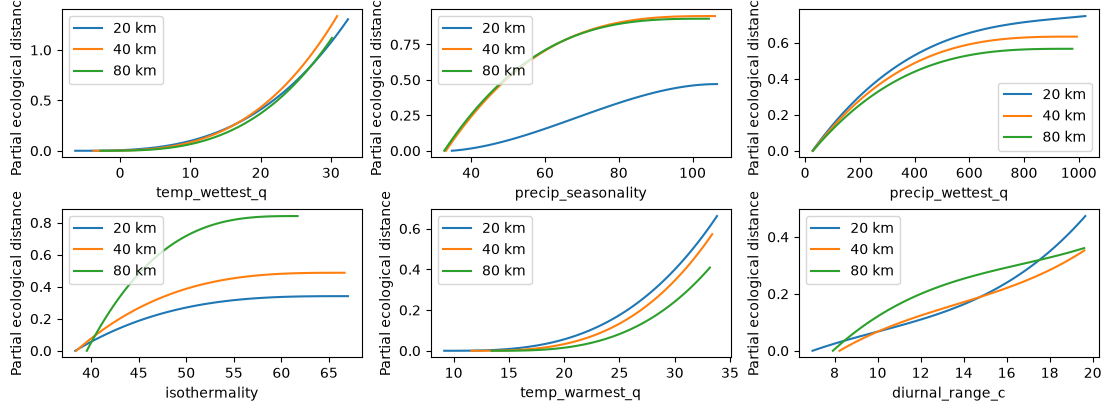

In [12]:
# Make the three observed-versus-predicted plots with 1:1 lines.
# Reuse climate_curve from Lab11 and calculate curves for all 19 predictors.
# Plot the three grains together for each predictor in a 5-by-4 panel layout.
# Label predictors and partial ecological distance; hide the unused panel.

# Sort bioclim variable importance by values, so we can look at only the most relevant ones
models = {}
predictions = {}
gdm_summary = pd.DataFrame()
importance = pd.DataFrame()

for grain in GRAINS:
    X = model_X[grain]
    y = model_y[grain]
    geography_only = GDM(geo=True, knots=0).fit(X[["xc", "yc", "time_idx"]], y)
    model = GDM(geo=True, knots=0).fit(X, y)
    models[grain] = model
    predictions[grain] = model.predict(X)
    gdm_summary.loc[grain, "n_sites"] = len(X)
    gdm_summary.loc[grain, "n_pairs"] = len(y)
    gdm_summary.loc[grain, "geography_only_deviance_pct"] = 100 * geography_only.explained_
    gdm_summary.loc[grain, "training_deviance_explained_pct"] = 100 * model.explained_
    for name, value in model.predictor_importance_.items():
        importance.loc[grain, name] = value

gdm_summary.index.name = "grain_km"
importance.index.name = "grain_km"
display(gdm_summary)
display(importance)

sorted_cols = importance.sum().sort_values(ascending=False).index
importance_sorted = importance[sorted_cols].drop(columns=['geo'])
importance_sorted

def climate_curve(model, X, predictor):
    curve = pd.DataFrame(index=range(100))
    for column in X.columns:
        curve[column] = X[column].median()
    curve[predictor] = np.linspace(X[predictor].min(), X[predictor].max(), 100)
    effect = model.gdm_transform(curve).sum(axis=1)
    effect = effect - effect[0]
    return pd.DataFrame({"value": curve[predictor], "effect": effect})


curves = {}

fig, axes = plt.subplots(2, 3, figsize=(11, 4), layout="constrained")
for ax, name in zip(axes.flat, importance_sorted.columns):
    for grain in GRAINS:
        curve = climate_curve(models[grain], model_X[grain], name)
        curves[(grain, name)] = curve
        ax.plot(curve.value, curve.effect, label=f"{grain} km")
    ax.set(xlabel=name, ylabel="Partial ecological distance")
    ax.legend()
fig.savefig(OUTPUT / "gdm_climate_curves_by_grain.png", dpi=150)
plt.show()

**Interpretation:** How much does adding climate improve training fit over
geography alone? Which environmental intervals show the most modeled change?
Which conclusions persist across grains? Explain why transformation heights
are not p-values, why a curve is not a habitat optimum, and why training
fit is not evidence of geographic transfer accuracy.

*Your answer:* There is a clear and substantial improvement in the fit of the model when climate data is included in the training. Temperature in the wettest quarter shows the most modeled change. All the environmental interval changes are pretty consistent across grains, except for isolthermality and  precipitation seasonality.

## 9. PCA map and biplot of expected composition

Adapt the PCA cell near the end of Lab11. Start with `pca_grain = 40`.
Sum each predictor's weighted spline components to make **19 transformed
columns**, then run PCA **without standardizing them**. This preserves the GDM
weights. Use the first two PC scores to color a California map and a PC1/PC2
scatterplot with the same color key. Report their explained-variance percentages.

Identify and label **only the two variables with the largest loading-vector
lengths across PC1 and PC2**. Calculate loadings as in the lab, then use
`sqrt(PC1_loading**2 + PC2_loading**2)` to measure each arrow's length. A signed
sum can cancel large loadings or change when an axis flips. Display the ranked
loadings table and draw the selected two arrows on the biplot. Also map those
two original climate variables to help interpret their spatial gradients.

Similar colors indicate similar climate-associated expected composition **in
the displayed two-component summary**. They do not encode richness or calibrated
Jaccard distance, and the remaining PCs may contain meaningful variation. GDM's
separate geographic-distance effect is excluded from the site-level
transformation. Each model's PCA and color scale are independent; do not compare
matching colors between states or separately fitted grains as a shared key.

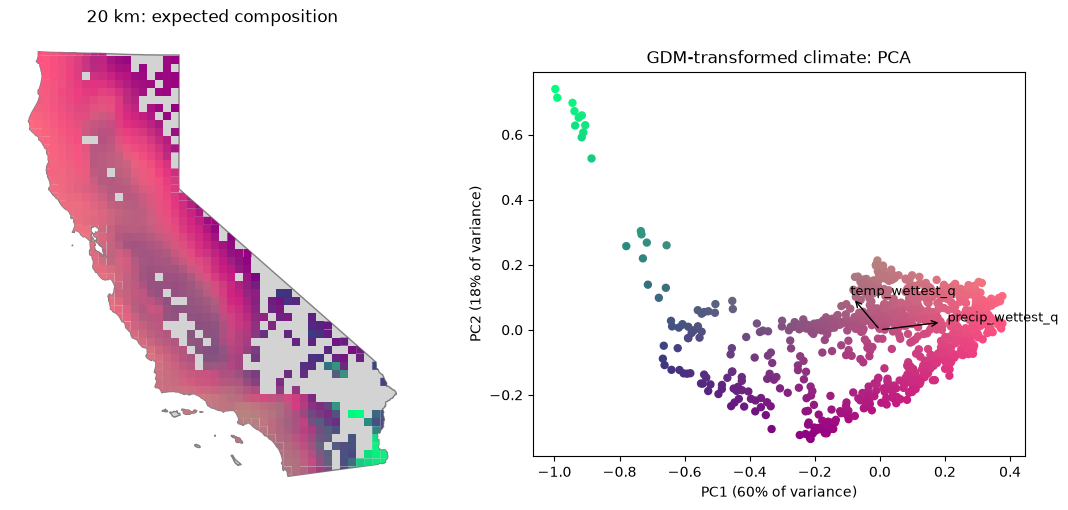

In [13]:
pca_grain = 40

# Adapt the Lab11 PCA map/biplot cell using all 19 predictors and california.
# Create a loadings table with PC1, PC2, and vector length for every predictor.
# Select the two longest vectors, display their names, and draw only their arrows.
# Save the PCA figure and map the two selected original climate variables.


from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler

pca_grain = 20  # Try 10 or 40 as well.
X_biplot = model_X[pca_grain]
model = models[pca_grain]

# Sum each predictor's weighted spline components.
weighted_splines = model.gdm_transform(X_biplot)
n_basis = model.preprocessor_.n_spline_bases_
transformed = pd.DataFrame(index=X_biplot.index)
for i, name in enumerate(predictors):
    start = i * n_basis
    stop = start + n_basis
    transformed[name] = weighted_splines[:, start:stop].sum(axis=1)

pca = PCA(n_components=2)
scores = pca.fit_transform(transformed)
scaled_scores = MinMaxScaler(clip=True).fit_transform(scores)
colors = np.column_stack([scaled_scores, np.full(len(scores), 0.5)])

fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
california.plot(ax=axes[0], color="lightgray", edgecolor="gray")
model_sites[pca_grain].loc[X_biplot.index].plot(ax=axes[0], color=colors)
axes[0].set_title(f"{pca_grain} km: expected composition")
axes[0].set_axis_off()

axes[1].scatter(scores[:, 0], scores[:, 1], c=colors, s=25)
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

# Get the predictors with the largest loadings
idx = np.argpartition(np.sum(np.abs(loadings), axis=1), -2)[-2:]

for i in idx:
    vector = loadings[i]
    name = predictors[i]
    axes[1].annotate("", xy=vector, xytext=(0, 0),
                     arrowprops={"arrowstyle": "->", "color": "black"})
    axes[1].text(vector[0] * 1.1, vector[1] * 1.1, name, fontsize=9)
axes[1].set(title="GDM-transformed climate: PCA",
            xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)",
            ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
axes[1].set_aspect("equal")
fig.savefig(OUTPUT / f"gdm_pca_biplot_{pca_grain}_km.png", dpi=150)
plt.show()

**Interpretation:** Which two variables have the longest loading vectors?
What fraction of transformed variation do the first two PCs retain? Where does
modeled composition change most strongly, and how do the selected climate
gradients relate to that pattern? Why might the longest PCA arrows differ from
the predictors with the largest GDM transformation heights? Compare the PCA map
with richness and neighbor dissimilarity. Why do these maps answer different
questions?

*Your answer:* Temperature at the wettest quarter and precipitation at the wettest quarter have the longest loading vectors. PC1 retained 60% of the variation while PC2 retains 18% of the variation. It changes most strongly in the southeastern region of California. The region is drier during the wettest quarter and hottest during the wettest quarter. The predictors may create an environmental barrier for some species that is not perfectly correlated with dissimilarity between species composition. This map is about how climate influences the species present in a community, not just diversity or richness. 

## 11. Save results and synthesize

Save the main site layers, community matrices, distance-band summaries, GDM
inputs and predictions, model-comparison tables, all 19 climate curves, the PCA loadings table, and PCA figures
in `OUTPUT`. Save sensitivity results with distinct names.

Write a **400–600 word synthesis** answering the main question: what can these
data tell us about spatial community composition in California, and which
conclusions depend on grain or sampling? Support it with numerical examples and
at least three figures. Identify one concrete additional survey or biological
dataset that would help distinguish competing explanations.

*Your synthesis:* The majority of amphibian records come from the coast. The measures of mean richness changes depending on the grain size. While the number of records stays consistent, the average richness increases as grain size increases. The mean richness at 20 km is 5.5 and 11.7 at 80km. The map of species richness across the state at different grain sizes also exemplifies the way using different grain sizes changes the result of our survey. All  the plot show  that the northwest and southwest coast have the highest species richness, but there is a stripe of high species richness cells that goes through the center of California in the 40km and 80km plots. I believe this stripe is the Sierra Nevada mountain range. We also have two maps at a grain size of 10 km, one that shows the number of records per cell, and one that shows the richness per cell. Together these maps show that richness is higher in areas with a higher number of records, although the two are not perfectly correlated. 

Grain size also changes the measurements of similarity of the species composition on a community. For example similarity because cells when using a grain size of 20 km is 0.85, but at 100 km the similarity is 0.56. For some reason the measure of similarity does not decrease linearly, I would have expected it to steadily decrease at grain size increased. Instead the similarity is the lowest (0.54) at 60 km and the second highest at 80 km. Regardless of the grain size the trend of the Jaccard similarity decreasing as the distance between cells increased remained consistent. The similarity decreased rapidly, leveled off, and then decreased rapidly again. When measuring dissimilarity within cells, the maps of dissimilarity at different grain sizes were relatively consistent.

The model that included the climate variables impacting each cell was better at explaining differences in the species composition between cells. The relationship between ecological dissimilarity and climate was consistent across grain sites for most climatic variables. The exceptions were precipitation seasonality which was far lower for 20km than for either 40 or 60km, and isothermally where the 80km grain size trendline had a steeper slope and was much higher than the 40 and 20km trendlines. According to the biplot, precipitation during the wettest quarter and temperature during the wettest quarter, where the most influential in determining the species composition of a cell. 
I recommend using a dataset that shows the range size for all the species we have sampled and a dataset that shows the average heterogeneity of climate in California compared to other US states and regions. This combined data could be used to choose the optimal grid size given the specific biotic and abiotic conditions of California rather than testing and comparing all three grain sizes.


Sources: [California data provenance and GBIF instructions](../data/CA_data_README.md),
[Lab11](../labs/Lab11-SpatialCommunityComposition.ipynb),
[GDM method](https://doi.org/10.1111/j.1472-4642.2007.00341.x), and
[gdmbayes](https://github.com/butterman0/gdmbayes).

In [14]:
# Save CSVs, GeoPackages, and figures with descriptive filenames.